In [1]:
# Final project - Data Science course by LearnIT - Katarzyna Banasik 
# Topic: Diagnostyka nowotworów z danych medycznych
# Dataset: Breast Cancer Wisconsin (sklearn)

In [34]:
# Problem definition: creating a ML model that will classify the new patient data based on the existing data on the breast cancer as at risk or not at risk of a breast cancer. 
# sufferers to recognize if a person with specific medical data also has a breast cancer.  
# The main beneficient of this ML algorithm is the patient who can learn if they have breast cancer or not. 
# The main user of this ML algorithm is a medical professional/radiologist.
# The ML model will be learning from the Breast Cancer Wisconsin (sklearn) dataset. The learning data is limited, this is just an example 
# of a real-world ML model that could detect cancer. 
# Hypothesis zero is that the next person has a breast cancer as well.
# I will try to find the model that has a high recall (accurately recognizes TP and has the lowest FN). Target recall > 85%

In [35]:
# DATA COLLECTION AND EDA

In [19]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

In [44]:
# Load data - function definition
def load_data():
    data = load_breast_cancer()
    df = pd.DataFrame(data.data, columns=data.feature_names)
    df['target'] = data.target
    print(f"Loaded: {df.shape}")
    return df

In [29]:
# Clean data function
def clean_data(df):
    # Drop duplicates
    df = df.drop_duplicates()
    return df

In [30]:
# Load the data
df = load_data()

Loaded: (569, 31)


In [31]:
# Clean the data
df_clean = clean_data(df)

In [40]:
# Print all the feature names
print(df.columns[:-1])

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='str')


In [32]:
# Display first few rows before cleaning
print("Before cleaning:")
print(df.head())

# Display first few rows after cleaning
print("\nAfter cleaning:")
print(df_clean.head())

Before cleaning:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area 

In [33]:
# Display basic statistics of the cleaned data
print("\nBasic Statistics:")
print(df_clean.describe())

# Display median of each column
print("\nMedians:")
print(df_clean.median())


Basic Statistics:
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000             0.

In [36]:
# Find outliers using IQR
Q1 = df_clean.quantile(0.25)
Q3 = df_clean.quantile(0.75)
IQR = Q3 - Q1

print("\nPotential Outliers:")
outliers = ((df_clean < (Q1 - 1.5 * IQR)) | (df_clean > (Q3 + 1.5 * IQR))).sum()
print(outliers)


Potential Outliers:
mean radius                14
mean texture                7
mean perimeter             13
mean area                  25
mean smoothness             6
mean compactness           16
mean concavity             18
mean concave points        10
mean symmetry              15
mean fractal dimension     15
radius error               38
texture error              20
perimeter error            38
area error                 65
smoothness error           30
compactness error          28
concavity error            22
concave points error       19
symmetry error             27
fractal dimension error    28
worst radius               17
worst texture               5
worst perimeter            15
worst area                 35
worst smoothness            7
worst compactness          16
worst concavity            12
worst concave points        0
worst symmetry             23
worst fractal dimension    24
target                      0
dtype: int64


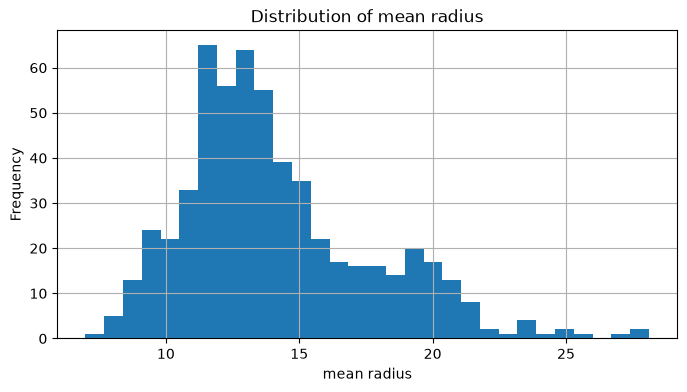

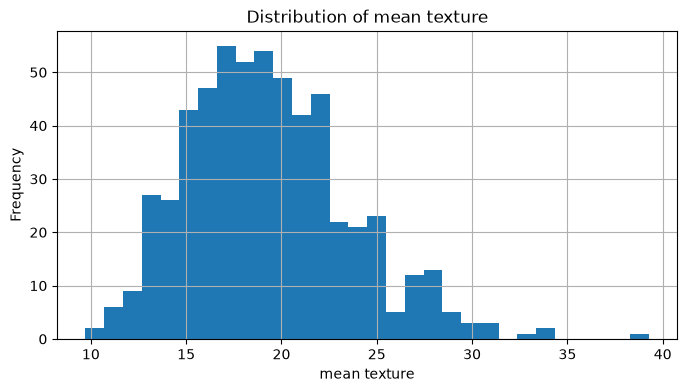

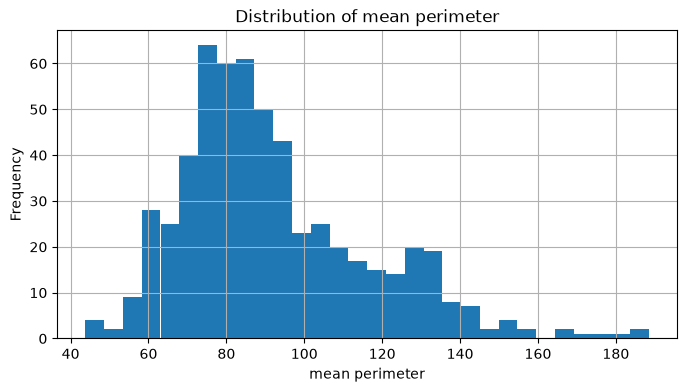

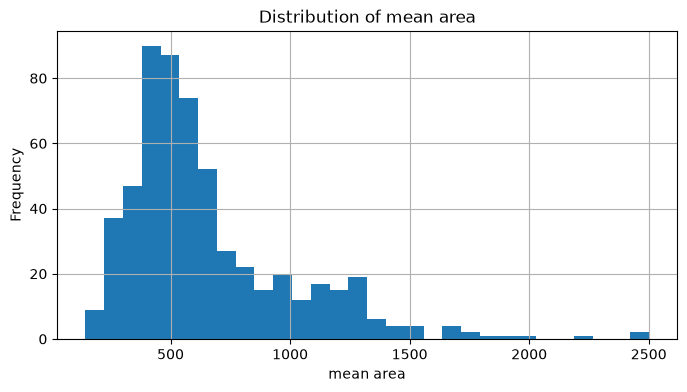

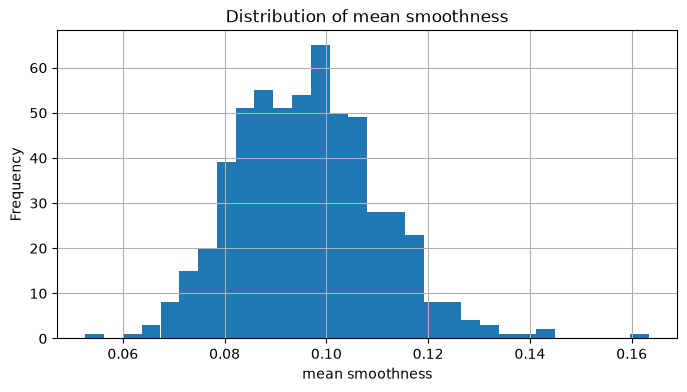

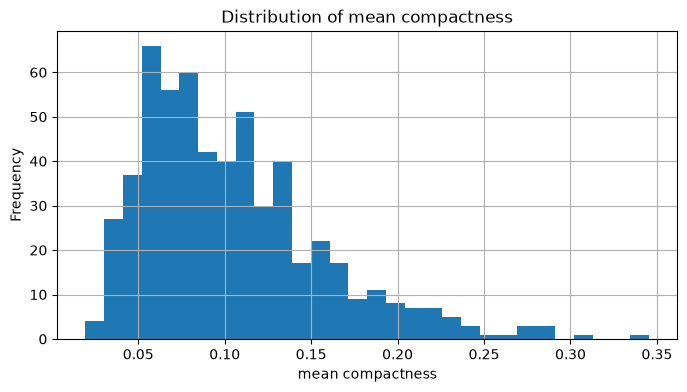

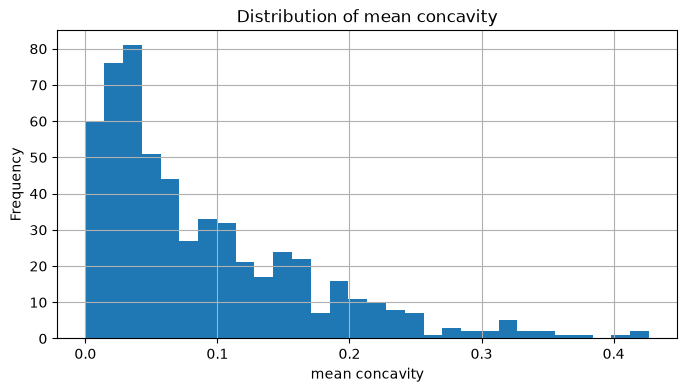

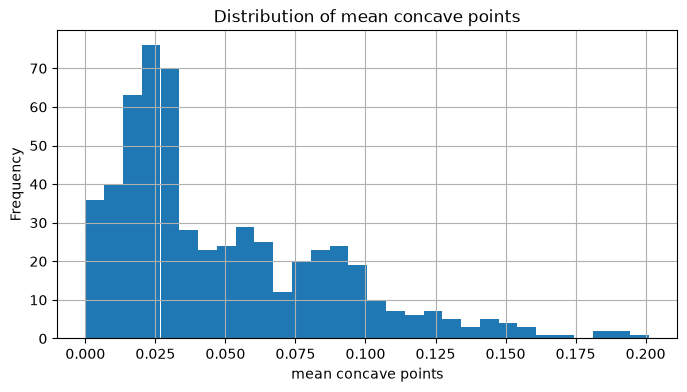

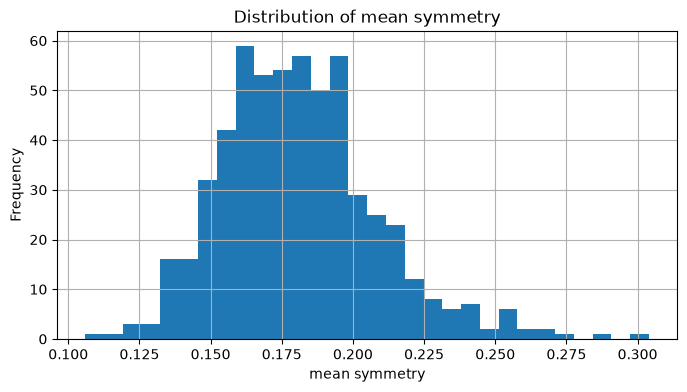

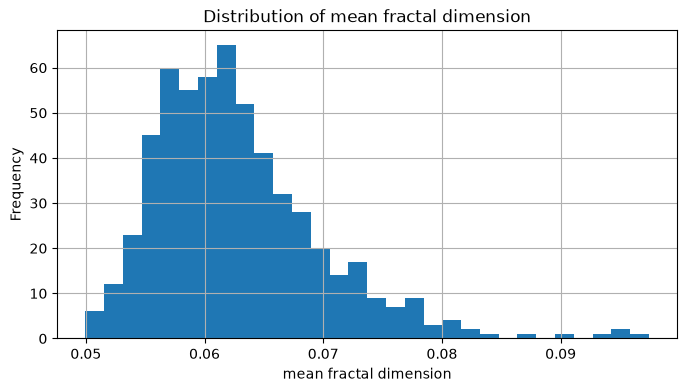

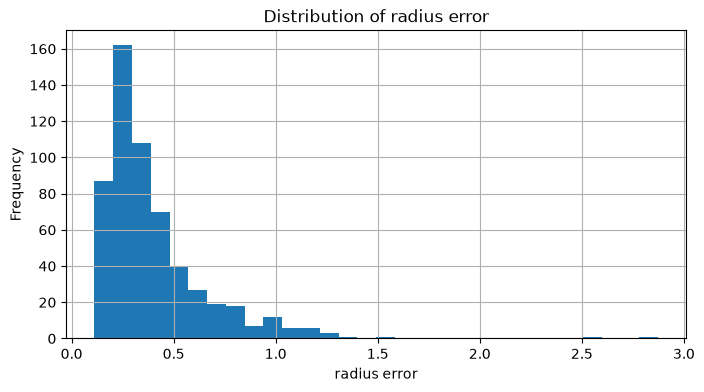

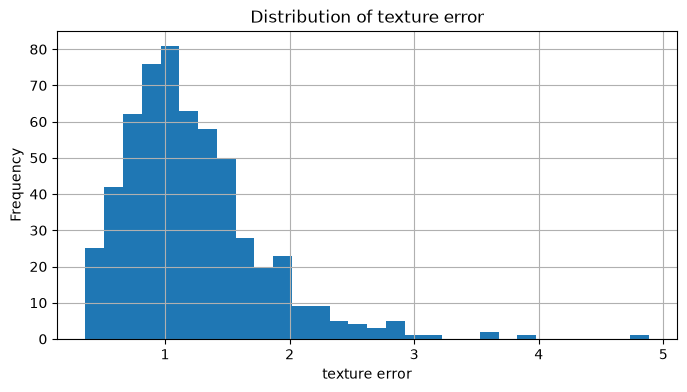

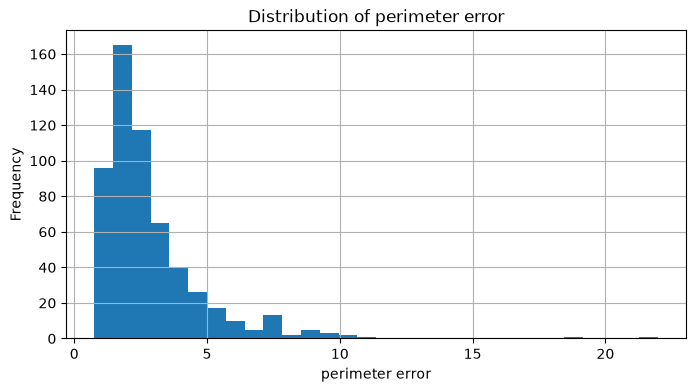

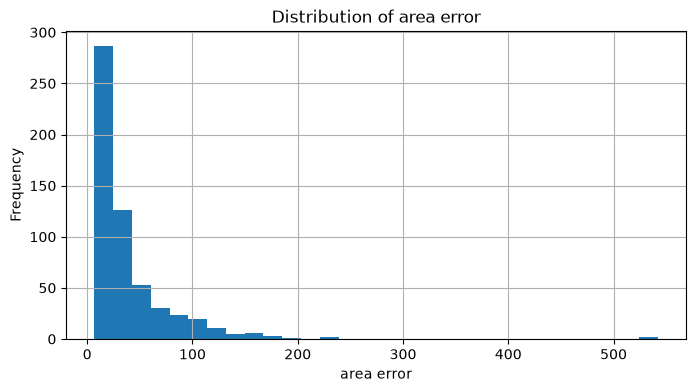

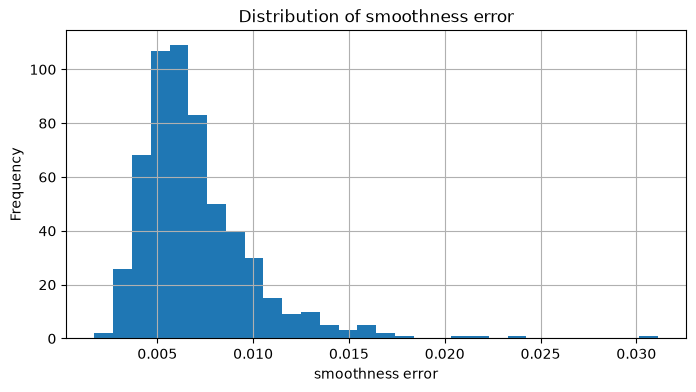

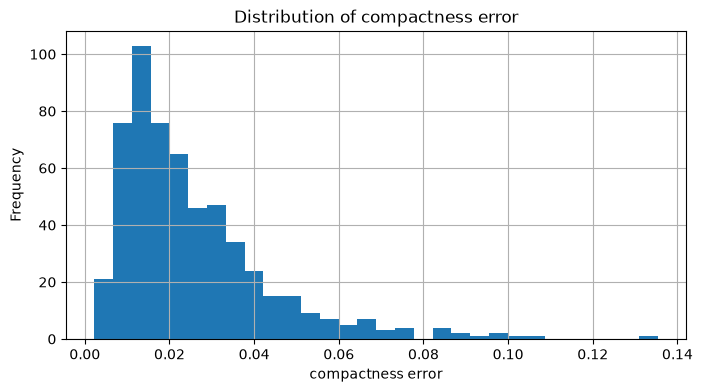

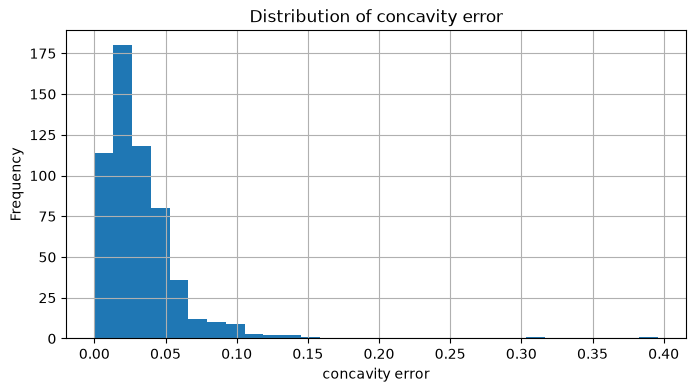

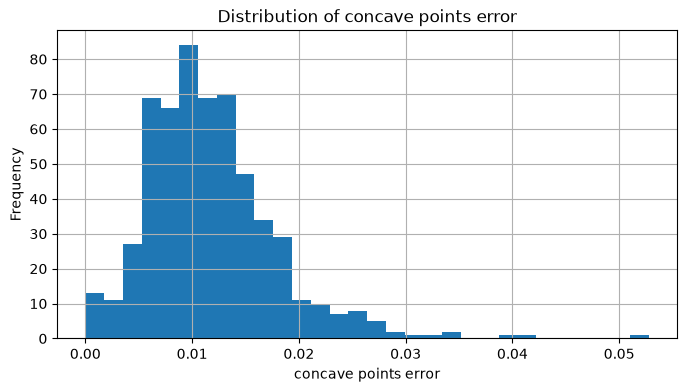

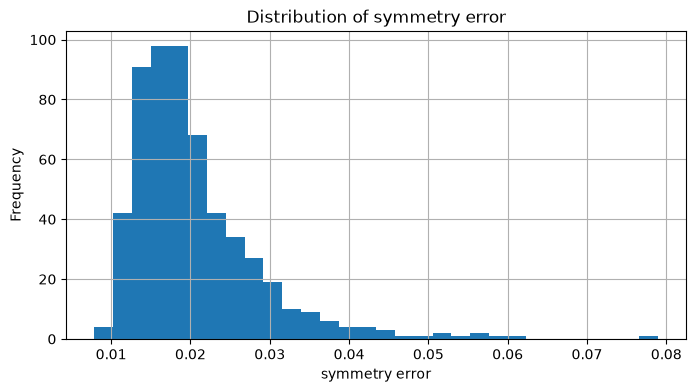

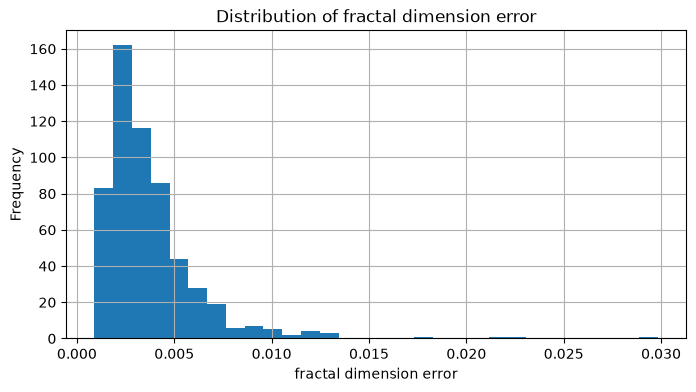

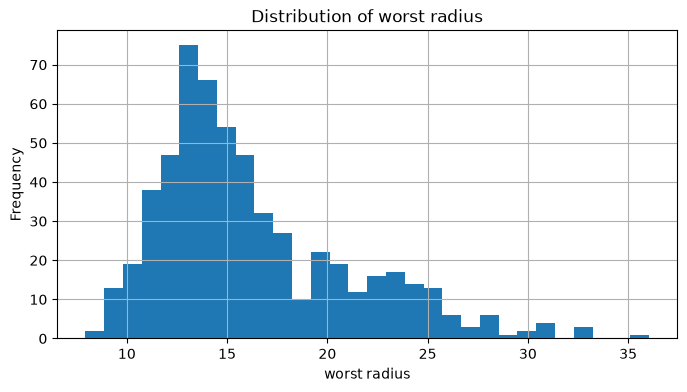

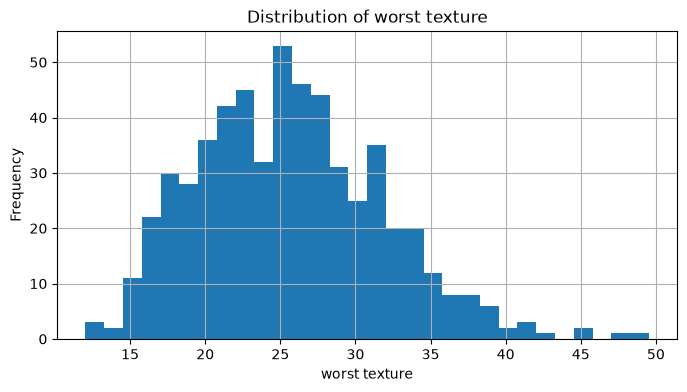

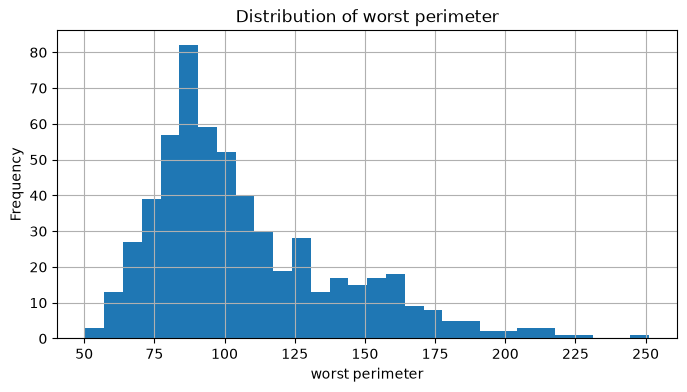

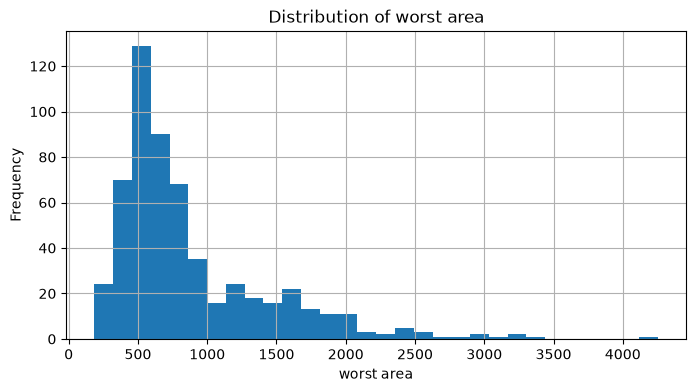

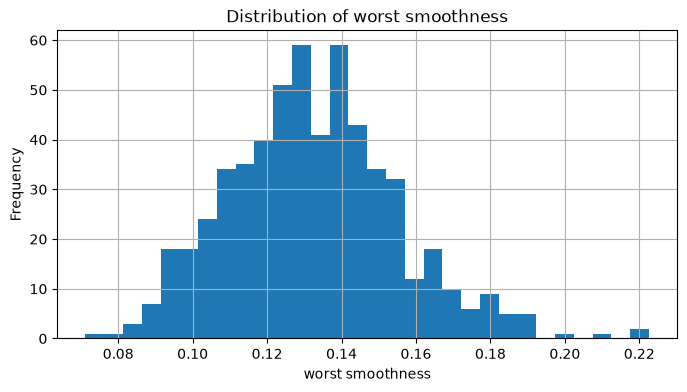

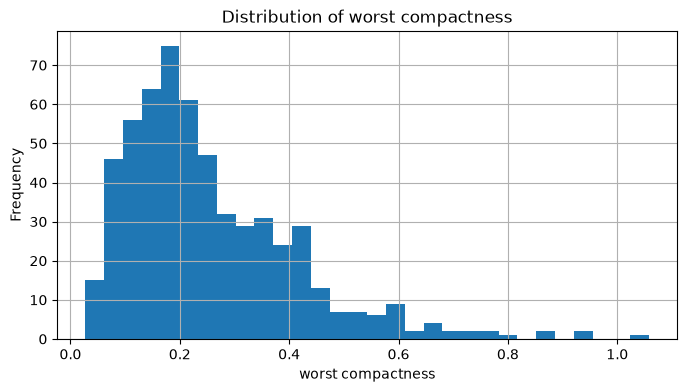

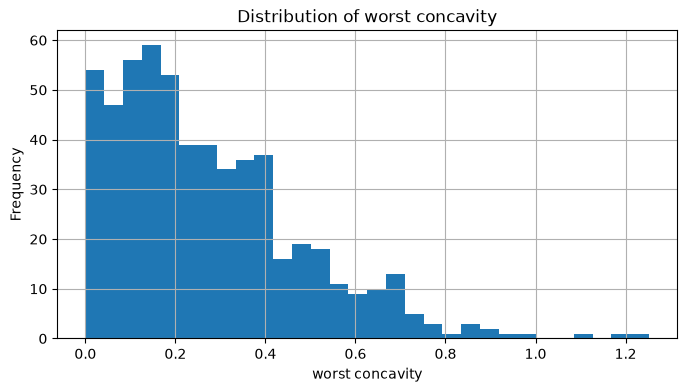

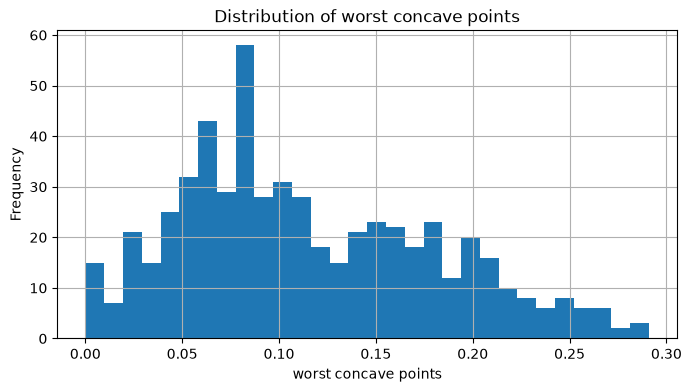

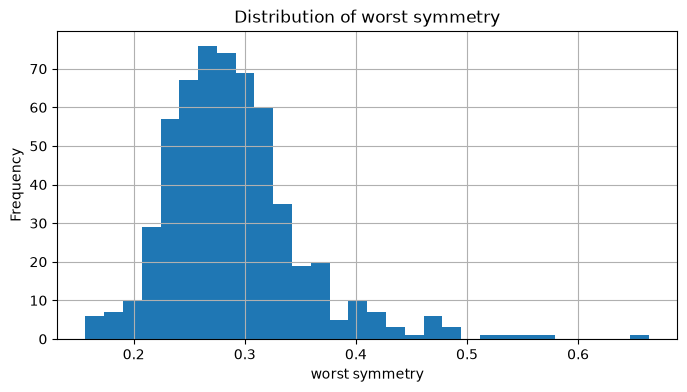

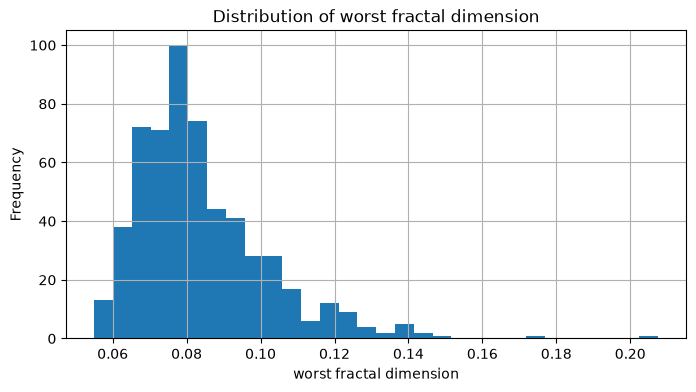

In [39]:
# Checking the outliers on a histogram plot 

import matplotlib.pyplot as plt

# Generate histograms for every feature in the dataset
def plot_histograms(df):
    features = df.columns[:-1]  # Exclude the target column
    for feature in features:
        plt.figure(figsize=(8, 4))
        df[feature].hist(bins=30)
        plt.title(f'Distribution of {feature}')
        plt.xlabel(feature)
        plt.ylabel('Frequency')
        plt.show()

plot_histograms(df_clean)

Conclusions from the EDA analysis, thinking about whether the data is useful for training a ML classification model. 

Presence of Outliers:

Outliers can exist in features due to variability in measurements or data entry errors.
Outliers can skew the results of metrics like mean and standard deviation.
They may lead to overfitting if the model tries to capture noise in the data rather than the actual pattern.

Feature Correlation:

Some features might be highly correlated. While useful for understanding, multicollinearity can affect certain algorithms.

This is why I decided to do data preprocessing before trainign my model. 

- scaling features and handling outliers through transformations
- evaluating feature importance and removing highly correlated or irrelevant features
- using cross-validation to ensure the model generalizes well
- using algorithms resilient to outliers and capable of handling multicollinearity, like tree-based models

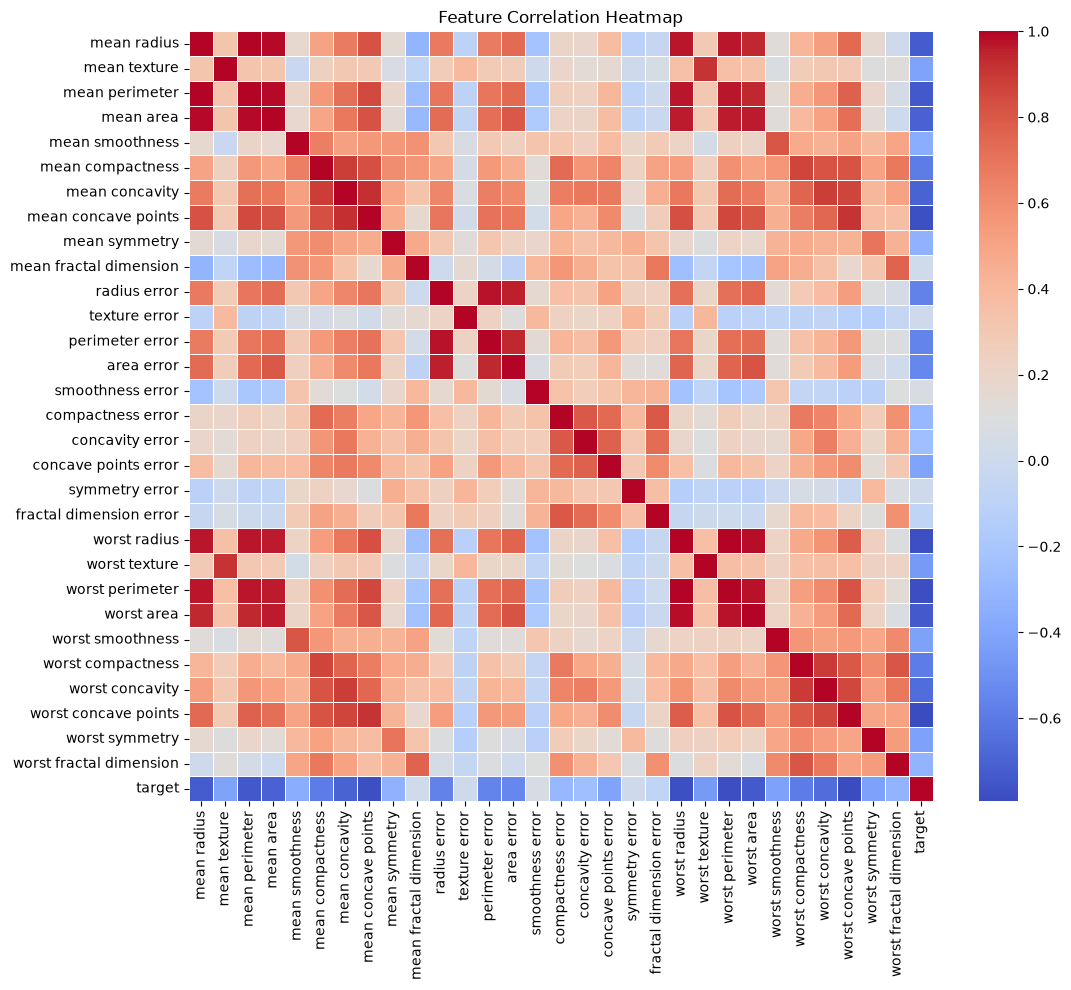

In [42]:
#Checking feature correlation
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

# Load the dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

# Calculate the correlation matrix
corr_matrix = df.corr()

# Plot the correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

Summary: Highly Correlated Features

Mean Features:

Mean Radius, Mean Perimeter, Mean Area: These show strong correlations. 

Worst Features:

Worst Radius, Worst Perimeter, Worst Area: Similar to the mean features, these are highly correlated. 

Mean Concavity, Mean Concave Points: These pairs are also highly correlated and might be redundant.

I could consider keeping only one of each set based on domain knowledge or further feature importance analysis, as they contribute similar information. I do not have domain knowledge nor anyone to consult it with, therefore I will reduce the features based on the importance analysis using Random Forest or use PCA to combine them depending on the results. 

In [48]:
from sklearn.datasets import load_breast_cancer

# Load the data
data = load_breast_cancer()

# Extract features and target
X = data.data           # Features
y = data.target         # Target

# Target names can be accessed as follows
target_names = data.target_names

print("Target names:", target_names)
# Output: Target names: ['benign' 'malignant']

Target names: ['malignant' 'benign']


In [55]:
## DATA CLEANING 
# I will normalize the dataset to help handle outliers and compare the features. 

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Load the dataset
data = load_breast_cancer()

# Create a DataFrame
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the min-max scaler
scaler = MinMaxScaler()

# Fit and transform the training set, transform the test set
X_train_normalized = scaler.fit_transform(X_train)
X_test_normalized = scaler.transform(X_test)


In [56]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Load the dataset
data = load_breast_cancer()

# Features and target
X = data.data
y = data.target

# You may want to create a DataFrame for better handling
df = pd.DataFrame(X, columns=data.feature_names)

# Split the data (optional but recommended for testing)
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.2, random_state=42)

# Initialize and fit the model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Get feature importances
importances = model.feature_importances_

# Create a DataFrame to see the importances
importance_df = pd.DataFrame({'Feature': data.feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

print(importance_df)

                    Feature  Importance
23               worst area    0.153892
27     worst concave points    0.144663
7       mean concave points    0.106210
20             worst radius    0.077987
6            mean concavity    0.068001
22          worst perimeter    0.067115
2            mean perimeter    0.053270
0               mean radius    0.048703
3                 mean area    0.047555
26          worst concavity    0.031802
13               area error    0.022407
21            worst texture    0.021749
25        worst compactness    0.020266
10             radius error    0.020139
5          mean compactness    0.013944
1              mean texture    0.013591
12          perimeter error    0.011303
24         worst smoothness    0.010644
28           worst symmetry    0.010120
16          concavity error    0.009386
4           mean smoothness    0.007285
19  fractal dimension error    0.005321
15        compactness error    0.005253
29  worst fractal dimension    0.005210


I will remove the features with below 0.01 importance to prevent overfitting. 

In [57]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Load the dataset
data = load_breast_cancer()

# Create a DataFrame from the data
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and fit the model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Get feature importances
importances = model.feature_importances_

# Create a DataFrame to view the importances
importance_df = pd.DataFrame({'Feature': data.feature_names, 'Importance': importances})

# Filter out features with importance below a threshold
threshold = 0.01
important_features = importance_df[importance_df['Importance'] >= threshold]['Feature'].tolist()

# Select only important features
X_train_reduced = X_train[important_features]
X_test_reduced = X_test[important_features]

print("Selected important features:\n", important_features)


Selected important features:
 ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean compactness', 'mean concavity', 'mean concave points', 'radius error', 'perimeter error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry']


In [58]:
# I will use PCA will reduce the dimensionality by creating principal components that capture the variance in the data. 
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.datasets import load_breast_cancer

# Load the dataset
data = load_breast_cancer()

# Create a DataFrame
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Select the highly correlated features for PCA
features_to_combine_mean = ["mean radius", "mean perimeter", "mean area"]
features_to_combine_worst = ["worst radius", "worst perimeter", "worst area"]
features_to_combine_concavity = ["mean concavity", "mean concave points"]

# Initialize PCA
pca = PCA(n_components=1)

# Apply PCA to each group of correlated features
mean_features_pca = pca.fit_transform(X[features_to_combine_mean])
worst_features_pca = pca.fit_transform(X[features_to_combine_worst])
concavity_features_pca = pca.fit_transform(X[features_to_combine_concavity])

# Create new DataFrame with PCA components replacing original features
X_combined = X.drop(columns=features_to_combine_mean + features_to_combine_worst + features_to_combine_concavity)

X_combined['mean_features_pca'] = mean_features_pca
X_combined['worst_features_pca'] = worst_features_pca
X_combined['concavity_features_pca'] = concavity_features_pca

# Split the new dataset
X_train, X_test, y_train, y_test = train_test_split(X_combined, y, test_size=0.2, random_state=42)

print("New feature set:")
print(X_combined.head())


New feature set:
   mean texture  mean smoothness  mean compactness  mean symmetry  \
0         10.38          0.11840           0.27760         0.2419   
1         17.77          0.08474           0.07864         0.1812   
2         21.25          0.10960           0.15990         0.2069   
3         20.38          0.14250           0.28390         0.2597   
4         14.34          0.10030           0.13280         0.1809   

   mean fractal dimension  radius error  texture error  perimeter error  \
0                 0.07871        1.0950         0.9053            8.589   
1                 0.05667        0.5435         0.7339            3.398   
2                 0.05999        0.7456         0.7869            4.585   
3                 0.09744        0.4956         1.1560            3.445   
4                 0.05883        0.7572         0.7813            5.438   

   area error  smoothness error  ...  worst texture  worst smoothness  \
0      153.40          0.006399  ...        

The X_combined dataset reflects the following changes:

- Normalization: Apply normalization to ensure consistent scaling.
- Feature Reduction: Remove features with low importance scores from the Random Forest analysis.
- PCA Transformation: Replace highly correlated features with PCA components.

ML MODEL DEVELOPMENT 
I will train a baseline model (Logistic Regression) and compare it with Random Forest, Support Vector Machine (SVM), Gradient Boosting, and K-Nearest Neighbors. My aim is to have recall >85% with low computing costs, energy-efficient. 

In [63]:
import mlflow
import mlflow.sklearn
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd
import time

# Prepare models
models = {
    "Baseline_LogisticRegression": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
    "KNN": KNeighborsClassifier()
}

results = []
mlflow.set_experiment("Breast_Cancer_Classification")

# Metrics to track
scoring = ['accuracy', 'precision', 'recall']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    print(f"Training {name}...")
    start_time = time.time()
    
    with mlflow.start_run(run_name=name):
        # Ensure X_combined is used here
        cv_results = cross_validate(model, X_combined, y, cv=cv, scoring=scoring)
        duration = time.time() - start_time
        
        # Calculate averages
        avg_recall = cv_results['test_recall'].mean()
        avg_precision = cv_results['test_precision'].mean()
        avg_acc = cv_results['test_accuracy'].mean()
        
        # Log to MLflow
        mlflow.log_param("model_name", name)
        mlflow.log_metric("recall", avg_recall)
        mlflow.log_metric("precision", avg_precision)
        mlflow.log_metric("accuracy", avg_acc)
        mlflow.log_metric("training_time", duration)
        
        results.append({
            "Model": name,
            "Recall": avg_recall,
            "Precision": avg_precision,
            "Accuracy": avg_acc,
            "Time": duration
        })

results_df = pd.DataFrame(results)
print(results_df)

Training Baseline_LogisticRegression...
Training RandomForest...
Training SVM...
Training GradientBoosting...


/Users/katarzyna.banasik/Library/Python/3.14/lib/python/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/katarzyna.banasik/Library/Python/3.14/lib/python/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/katarzyna.banasik/Library/Python/3.14/lib/python/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/katarzyna.banasik/Library/Python/3.14/lib/python/site-packages/sklearn/svm/_base.py:236

Training KNN...
                         Model    Recall  Precision  Accuracy      Time
0  Baseline_LogisticRegression  0.971987   0.951376  0.950831  0.164690
1                 RandomForest  0.974883   0.967067  0.963111  0.455271
2                          SVM  0.974804   0.912071  0.924422  0.054366
3             GradientBoosting  0.971987   0.956506  0.954324  0.860324
4                          KNN  0.960837   0.938657  0.935010  0.028718


The highest recall 0.974883 and precision 0.967067 is with the Random Forest algorithm. I care mostly about the recall as I want to catch all TP and reduce FN. The calculation time is high but not the highest as the highest has Gradient Boosting so I consider it good performance/energy usage ratio. I will continue using Random Forest as my choice for this project for these reasons. 
    

I will use RandomizedSearchCV to fine-tune the RandomForest model. 

In [64]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
import mlflow

best_model = RandomForestClassifier(random_state=42)
param_dist = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

# Use RandomizedSearchCV with scoring set to 'recall'
random_search = RandomizedSearchCV(
    best_model, param_distributions=param_dist, n_iter=10, 
    scoring='recall', cv=cv, n_jobs=-1, random_state=42
)

with mlflow.start_run(run_name="RandomForest_Tuned"):
    random_search.fit(X_combined, y)
    
    # Log best parameters and metrics
    mlflow.log_params(random_search.best_params_)
    mlflow.log_metric("best_recall", random_search.best_score_)
    
    print(f"Best Parameters: {random_search.best_params_}")
    print(f"Best Recall: {random_search.best_score_}")


Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'max_depth': 20}
Best Recall: 0.977699530516432


The Best Recall is slightly higher than the baseline RandomForest model which was 0.97488, by approx. 0.003 higher.

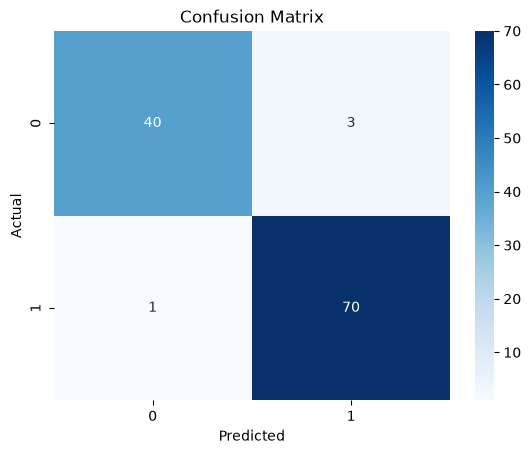

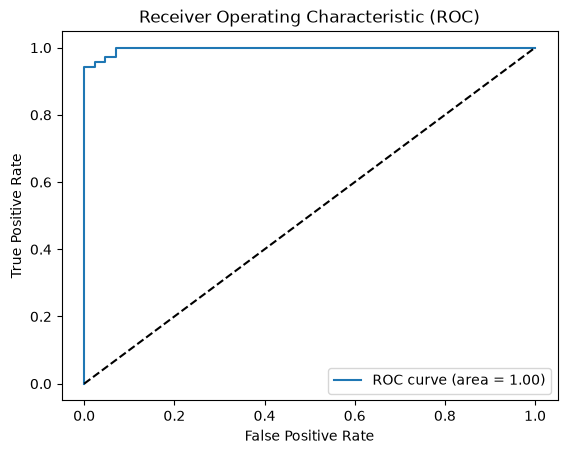

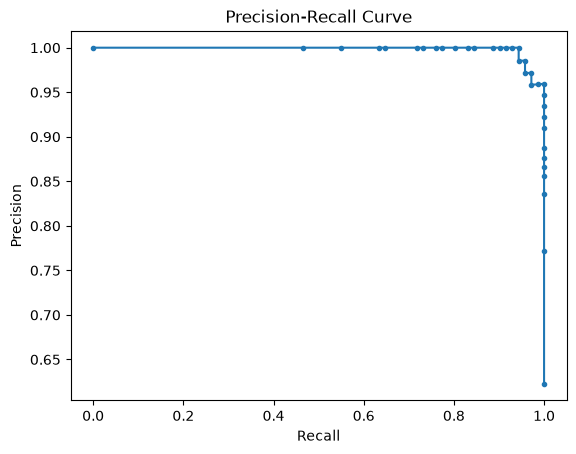

Classification Report:
               precision    recall  f1-score   support

   malignant       0.98      0.93      0.95        43
      benign       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



AssertionError: The shape of the shap_values matrix does not match the shape of the provided data matrix.

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve, classification_report
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

# X_combined is the new dataset with normalization, reduced feature list and PCA applied to highly correlated features

data = load_breast_cancer()
X, y = data.data, data.target

pca = PCA(n_components=1, random_state=42)
X_combined = X.copy()

X_combined[:, :3] = pca.fit_transform(X[:, :3]) 

# Splitting the data into train and test data
X_train, X_test, y_train, y_test = train_test_split(X_combined, y, test_size=0.2, random_state=42)

# Training the Random Forest model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
plt.plot(recall, precision, marker='.')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.show()

# Classification Report
report = classification_report(y_test, y_pred, target_names=data.target_names)
print("Classification Report:\n", report)

# Feature Importance using SHAP
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values[1], X_test, feature_names=["PCA Component 1"] + list(data.feature_names[3:]))

# Error Analysis
errors = X_test[y_test != y_pred]
print(f"Number of misclassified samples: {len(errors)}")

# Compare with Baseline
from sklearn.linear_model import LogisticRegression
baseline_model = LogisticRegression(max_iter=10000)
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)
baseline_report = classification_report(y_test, baseline_pred, target_names=data.target_names)
print("Baseline Classification Report:\n", baseline_report)


Results analysis: 

Confusion matrix: 
Confusion matrix shows that we have 40 true negative (TN) cases, 1 predicted as negative but actually malignant cancer (false negative, FN), 70 true positive (TP) cases so predicted as malignant and was actually malignant and 3 predicted as malignant and actually benign cases (false positive, FP). It means one case of malignant tumor was actually missed. It is a good ratio, however, in the medical industry we always aim to have as close to 0 as possible of false negatives. 

ROC curve:
The ROC curve indicates excellent model performance:
True Positive Rate (TPR): Approaches 1 quickly, indicating high sensitivity.
False Positive Rate (FPR): Remains low for the majority of thresholds.

Precision-recall curve:
Precision and Recall: Both are consistently high across the curve, indicating a strong balance between false positives and false negatives.

Summary:
The model is highly precise and accurate in identifying both malignant and benign cases.
In cancer detection, maintaining high recall is crucial; the curve and metrics suggest achieving this while retaining strong precision.